I receive from Role 1 : 
Occupancy grid (Matrix of 0 and 1), Robot position(x, y), Robot heading	theta, Goal position (x, y)	Destination
Grid resolution	(Conversion en coordonnées réelles), Map origin
En attendant :

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from heapq import heappush, heappop # used if you want to use heap queue for priority queue (easier to implement) but not compulsory

In [ ]:
Map = np.zeros((11, 9))

Map[0, :] = -1; Map[10, :] = -1; Map[:, 0] = -1; Map[:, 8] = -1
Map[8, 1] = -1; Map[9, 1] = -1; Map[9, 2] = -1; Map[4:6, 4:8] = -1
start = (8, 5) 
goal = (2, 6)

resolution = 0.02

In [ ]:
Map = np.zeros((5, 5))

# Bordures extérieures
Map[0, :] = -1
Map[4, :] = -1
Map[:, 0] = -1
Map[:, 4] = -1

# Obstacles intérieurs
Map[3,1] = -1
Map[1,3] = -1
Map[4,2] = -1
Map[2,4] = -1

# Départ et arrivée
start = (1, 1)
goal = (3, 3)

In [28]:

Map = np.zeros((20, 25))

# Bordures extérieures
Map[0, :] = -1
Map[19, :] = -1
Map[:, 0] = -1
Map[:, 24] = -1

# Groupe 1 : obstacles en haut à gauche
Map[2, 2:10] = -1
Map[3:7, 9] = -1
Map[6, 3:9] = -1

# Groupe 2 : obstacles en haut au centre
Map[2:8, 13] = -1
Map[4, 13:19] = -1
Map[7, 15:22] = -1
Map[2, 18:23] = -1

# Groupe 3 : obstacles au centre gauche
Map[9:15, 3] = -1
Map[10, 3:10] = -1
Map[14, 5:12] = -1
Map[11:14, 10] = -1

# Groupe 4 : obstacles au centre
Map[9, 13:20] = -1
Map[10:15, 17] = -1
Map[14, 14:18] = -1

# Groupe 5 : obstacles au centre droit
Map[9:13, 22] = -1
Map[12, 19:23] = -1
Map[15, 20:24] = -1

# Groupe 6 : obstacles en bas à gauche
Map[16, 2:8] = -1
Map[13:18, 7] = -1
Map[17, 10:16] = -1

# Groupe 7 : obstacles en bas au centre
Map[15:19, 12] = -1
Map[15, 13:19] = -1
Map[18, 17:22] = -1

# Départ et arrivée
start = (18, 1)
goal = (18, 13)

In [6]:
def display_map(map_grid, path, start, goal, explored):

    map_display = np.full(map_grid.shape, 'white', dtype=object)

    # Obstacles
    map_display[map_grid == -1] = 'black'

    # Cases explorées
    for position in explored:
        if map_display[tuple(position)] == 'white':
            map_display[tuple(position)] = 'grey'

    # Chemin
    for position in path:
        if map_display[position[0], position[1]] in ['white', 'grey']:
            map_display[position[0], position[1]] = 'blue'  # Path

    # Départ et arrivée : toujours prioritaires
    map_display[start[0], start[1]] = 'green'
    map_display[goal[0], goal[1]] = 'red'

    color_mapping = {
        'white': 0,
        'black': 1,
        'blue': 2,
        'green': 3,
        'red': 4,
        'grey': 5
    }

    cmap = ListedColormap([
        'white', 'black', 'blue', 'green', 'red', 'grey'
    ])

    map_numeric_display = np.vectorize(color_mapping.get)(map_display)

    fig, ax = plt.subplots(figsize=(4, 4))
    ax.imshow(map_numeric_display, cmap=cmap, vmin=0, vmax=5)

    ax.set_xticks(np.arange(-0.5, map_grid.shape[1], 1))
    ax.set_yticks(np.arange(-0.5, map_grid.shape[0], 1))
    ax.grid(True, color='gray')
    ax.set_xticklabels([])
    ax.set_yticklabels([])

    plt.show()

In [105]:
#print("Initial Map (0: free, -1: obstacle, 2: weighted cell):")
#print(Map)
#ALGO = "Initial Map"
#display_map(Map, [], SearchStart, SearchGoal, [])

In [7]:
def heuristic(a, b):
    # Implement the Manhattan distance heuristic
    return abs(a[0] - b[0]) + abs(a[1] - b[1])

In [8]:
def grid_search(map_grid, S, G):
    
    ## initialize the varibales above
    came_from = {}      # to reconstruct path
    g_costs = {S: 0}    # cost from start to the cell
    explored = set()    # to keep track of explored cells
    operation_count = 0 # to count the number of operations
    open_set = [(heuristic(S, G), 0, S)]  # priority queue for A* (f_cost, g_cost, position)
        
    while open_set: # G goal is unmarked
        current_f_cost, current_g_cost, current_pos = heappop(open_set)

        explored.add(current_pos)
        
        if current_pos == G: # if G goal is marked
            break

        # Get neighbors (up, down, left, right)
        neighbors = [
            (current_pos[0]-1, current_pos[1]),  # Up
            (current_pos[0]+1, current_pos[1]),  # Down
            (current_pos[0], current_pos[1]-1),  # Left
            (current_pos[0], current_pos[1]+1)   # Right
        ]

        for neighbor in neighbors: # for each neighbor of marked cells
            # Check if neighbor is within bounds
            if (0 <= neighbor[0] < map_grid.shape[0]) and (0 <= neighbor[1] < map_grid.shape[1]): #check if the neighbor is less than 1 and greater than 0
                # Check if neighbor is not an obstacle
                if map_grid[neighbor[0], neighbor[1]] != -1:
                    tentative_g_cost = current_g_cost + 1  + map_grid[neighbor[0], neighbor[1]]

                    if neighbor not in g_costs or tentative_g_cost < g_costs[neighbor]:
                        g_costs[neighbor] = tentative_g_cost
                        came_from[neighbor] = current_pos
                        operation_count += 1 
                        f_cost = tentative_g_cost + heuristic(neighbor, G)
                        heappush(open_set, (f_cost, tentative_g_cost, neighbor))
                        
    # Reconstruct path
    if current_pos == G:
        path = []
        while current_pos != S:
            path.append(current_pos)
            current_pos = came_from[current_pos]
        path.append(S)
        path.reverse()
        return path, explored, operation_count  # Return reversed path and explored cells
    else:
    # If we reach here, no path was found
        return None, explored, operation_count

In [19]:
##Comparaison avec Djikstra's algorithm
def grid_search2(map_grid, S, G):
    
    ## initialize the varibales above
    came_from = {}      # to reconstruct path
    g_costs = {S: 0}    # cost from start to the cell
    explored = set()    # to keep track of explored cells
    operation_count = 0 # to count the number of operations
    open_set = [(0, S)]  # priority queue for Dijkstra (cost, position)
       
        
    while open_set: # G goal is unmarked
        current_g_cost, current_pos = heappop(open_set)

        explored.add(current_pos)
        
        if current_pos == G: # if G goal is marked
            break

        # Get neighbors (up, down, left, right)
        neighbors = [
            (current_pos[0]-1, current_pos[1]),  # Up
            (current_pos[0]+1, current_pos[1]),  # Down
            (current_pos[0], current_pos[1]-1),  # Left
            (current_pos[0], current_pos[1]+1)   # Right
        ]

        for neighbor in neighbors: # for each neighbor of marked cells
            # Check if neighbor is within bounds
            if (0 <= neighbor[0] < map_grid.shape[0]) and (0 <= neighbor[1] < map_grid.shape[1]): #check if the neighbor is less than 1 and greater than 0
                # Check if neighbor is not an obstacle
                if map_grid[neighbor[0], neighbor[1]] != -1:
                    tentative_g_cost = current_g_cost + 1  + map_grid[neighbor[0], neighbor[1]]

                    if neighbor not in g_costs or tentative_g_cost < g_costs[neighbor]:
                        g_costs[neighbor] = tentative_g_cost
                        came_from[neighbor] = current_pos
                        operation_count += 1 
                        heappush(open_set, (tentative_g_cost, neighbor))
                        
    # Reconstruct path
    if current_pos == G:
        path = []
        while current_pos != S:
            path.append(current_pos)
            current_pos = came_from[current_pos]
        path.append(S)
        path.reverse()
        return path, explored, operation_count  # Return reversed path and explored cells
    else:
    # If we reach here, no path was found
        return None, explored, operation_count


In [9]:
def heuristic_oct(a, b):
    dx = abs(a[0] - b[0])
    dy = abs(a[1] - b[1])
    return max(dx, dy) + (np.sqrt(2) - 1) * min(dx, dy)

In [10]:
def grid_search_oct(map_grid, S, G):
    
    ## initialize the varibales above
    came_from = {}      # to reconstruct path
    g_costs = {S: 0}    # cost from start to the cell
    explored = set()    # to keep track of explored cells
    operation_count = 0 # to count the number of operations
    open_set = [(heuristic_oct(S, G), 0, S)]  # priority queue for A* (f_cost, g_cost, position)
        
    while open_set: # G goal is unmarked
        current_f_cost, current_g_cost, current_pos = heappop(open_set)

        explored.add(current_pos)
        
        if current_pos == G: # if G goal is marked
            break

        # Get neighbors (up, down, left, right)
        neighbors = [
            (current_pos[0]-1, current_pos[1]),  # Up
            (current_pos[0]+1, current_pos[1]),  # Down
            (current_pos[0], current_pos[1]-1),  # Left
            (current_pos[0], current_pos[1]+1),  # Right
            (current_pos[0]-1, current_pos[1]-1),  # Up-Left
            (current_pos[0]-1, current_pos[1]+1),  # Up-Right
            (current_pos[0]+1, current_pos[1]-1),  # Down-Left
            (current_pos[0]+1, current_pos[1]+1)   # Down-Right
        ]

        for neighbor in neighbors: # for each neighbor of marked cells
            # Check if neighbor is within bounds
            if (0 <= neighbor[0] < map_grid.shape[0]) and (0 <= neighbor[1] < map_grid.shape[1]): #check if the neighbor is less than 1 and greater than 0
                # Check if neighbor is not an obstacle
                if map_grid[neighbor[0], neighbor[1]] != -1:
                    if neighbor[0] != current_pos[0] and neighbor[1] != current_pos[1]:  # Diagonal movement
                        # avoid corner cutting
                        dx = neighbor[0] - current_pos[0]
                        dy = neighbor[1] - current_pos[1]
                        if map_grid[current_pos[0] + dx, current_pos[1]] == -1 or map_grid[current_pos[0], current_pos[1] + dy] == -1: 
                            # or = rèfle strict, si un des 2 est un obstacle il n'emprunte pas la diag, remplacer par AND si sûre que pas dangereux
                            continue
                        move_cost = np.sqrt(2)
                    else: # Straight movement
                        move_cost = 1

                    tentative_g_cost = current_g_cost + move_cost  + map_grid[neighbor[0], neighbor[1]]

                    if neighbor not in g_costs or tentative_g_cost < g_costs[neighbor]:
                        g_costs[neighbor] = tentative_g_cost
                        came_from[neighbor] = current_pos
                        operation_count += 1 
                        f_cost = tentative_g_cost + heuristic_oct(neighbor, G)
                        heappush(open_set, (f_cost, tentative_g_cost, neighbor))
                        
    # Reconstruct path
    if current_pos == G:
        path = []
        while current_pos != S:
            path.append(current_pos)
            current_pos = came_from[current_pos]
        path.append(S)
        path.reverse()
        return path, explored, operation_count  # Return reversed path and explored cells
    else:
    # If we reach here, no path was found
        return None, explored, operation_count

In [ ]:
def grid_to_world(path, resolution, origin_x, origin_y):
    waypoints = []
    for row, col in path:
        # rows aug towards bottom, cols aug towards right, in cart frame, so does our frame
        # center of each cell avoid center of robot neer lim of cells
        x = origin_x + (col + 0.5) * resolution
        y = origin_y - (row + 0.5) * resolution
        waypoints.append((x, y))
    return waypoints

In [38]:
def world_to_grid(x, y, resolution, origin_x, origin_y):
    col = int((x - origin_x) / resolution)
    row = int((y - origin_y) / resolution)
    return (row, col)

In [43]:
## essai 
point = (6, 3)
resolution = 0.1
origin_x = 0
origin_y = 0

obstacle_x = 0.35
obstacle_y = 0.65

world = grid_to_world([point], resolution, origin_x, origin_y)[0]

recovered = world_to_grid(
    world[0], world[1],
    resolution, origin_x, origin_y
)

print(point)
print(world)
print(recovered)

(6, 3)
(0.35000000000000003, 0.65)
(6, 3)


In [ ]:
def nav(map_grid, S, G, type_of_dist):
    display_map(map_grid, [], S, G, [])

    if type_of_dist == "Manhattan":
        path, explored, operation_count = grid_search(map_grid, S, G)
    elif type_of_dist == "Octile":
        path, explored, operation_count = grid_search_oct(map_grid, S, G)
    elif type_of_dist == "Dijkstra":
        path, explored, operation_count = grid_search2(map_grid, S, G)

    if path :
        print("Path length =", len(path)-1, "\n", path)
        print("Length explored:", len(explored))
        display_map(map_grid, path, S, G, explored)
    else:
        print("No path found with A*")

    waypoints = grid_to_world(path, resolution, 0, 0)

    return waypoints
    

In [35]:
#nav(Map, start, goal, "Octile")

-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

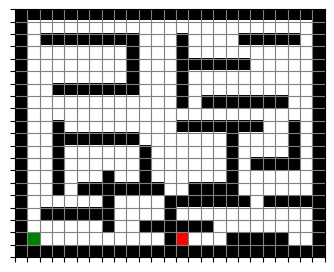

Path length = 44 
 [(18, 1), (17, 1), (16, 1), (15, 1), (14, 2), (13, 2), (12, 2), (11, 2), (10, 2), (9, 2), (8, 2), (8, 3), (8, 4), (8, 5), (8, 6), (8, 7), (8, 8), (8, 9), (8, 10), (8, 11), (8, 12), (8, 13), (8, 14), (8, 15), (8, 16), (8, 17), (8, 18), (8, 19), (8, 20), (9, 20), (10, 20), (11, 19), (11, 18), (12, 18), (13, 18), (14, 19), (15, 19), (16, 19), (17, 18), (17, 17), (17, 16), (18, 16), (18, 15), (18, 14), (18, 13)]
Length explored: 237


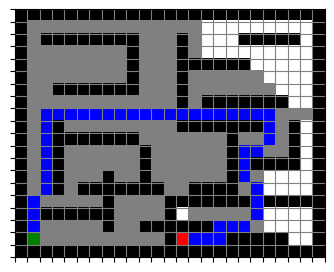

KeyboardInterrupt: 

In [36]:
state = "INIT"

while True:
    if state == "INIT":
        #get map, start, goal
        Map = Map
        SearchStart = start
        SearchGoal = goal
        state = "PLAN"

    elif state == "PLAN":
        #plan path with A*
        #smooth path
        #transfer waypoints
        path_found = nav(Map, SearchStart, SearchGoal, "Octile")
        if path_found:
            state = "MOVE"
        else:
            state = "ERROR" 

    elif state == "MOVE":
        #follow path
        #get the sensors mes
        goal_reached = False
        obstacle_detected = False

        if goal_reached:
            state = "DONE"
        elif obstacle_detected:
            state = "OBST_DETECTED"
    
    elif state == "OBST_DETECTED":
        #eval if path can still followable
        path_still_valid = True  # Placeholder for actual path validation logic
        if path_still_valid:
            state = "MOVE"
        else:
            state = "REPLAN"
    
    elif state == "REPLAN":
        #act map
        # get act pos°
        # replan path with A*

        state = "PLAN"
    
    elif state == "DONE":
        #stop
        break

    elif state == "ERROR":
        #stop and signal pbm
        break